## 0. Setup

In [ ]:
import os, re, time, math, random, collections, difflib
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cpu


## 1. Dataset


In [ ]:
DATA_PATH = "dataset_id_en.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"{DATA_PATH} tidak ditemukan. Taruh di folder yang sama dengan notebook ini.")

df = pd.read_csv(DATA_PATH)
print("Jumlah pasangan kalimat:", len(df))
df.head(8)

Saving dataset_id_en.csv to dataset_id_en.csv
Jumlah pasangan kalimat: 6000


,id,en
0,Kemarin saya melihat rumah lama itu di sekolah...,Yesterday I saw the old house at school and Bu...
1,Kemarin mahasiswa menjual sepatu itu di toko k...,Yesterday the student sold the shoe in the sho...
2,Sekarang dokter membeli sepeda itu di perpusta...,Now the doctor buys the bicycle at the library...
3,Hari ini guru membawa kue lama itu di pasar.,Today the teacher brings the old cake at the m...
4,Siti akan mengambil rumah baru itu di rumah ke...,Siti will take the new house at home then Siti...
5,Mereka akan membawa topi hitam itu di toko besok.,They will bring the black hat in the shop tomo...
6,Saya akan membeli mobil bagus itu di toko ming...,I will buy the good car in the shop next week.
7,Saya akan membeli kue itu minggu depan tetapi ...,I will buy the cake next week but the student ...


## 2. Preprocessing dasar
Lowercase, pisahkan tanda baca dari kata, rapikan spasi. Preprocessing yang sama dipakai oleh semua kelompok.

In [ ]:
def clean(s):
    s = str(s).lower().strip()
    s = re.sub(r"([.,!?])", r" \1 ", s)
    s = re.sub(r"\s+", " ", s).strip()
    return s

df["id_clean"] = df["id"].apply(clean)
df["en_clean"] = df["en"].apply(clean)
df[["id_clean", "en_clean"]].head(5)

,id_clean,en_clean
0,kemarin saya melihat rumah lama itu di sekolah...,yesterday i saw the old house at school and bu...
1,kemarin mahasiswa menjual sepatu itu di toko k...,yesterday the student sold the shoe in the sho...
2,sekarang dokter membeli sepeda itu di perpusta...,now the doctor buys the bicycle at the library...
3,hari ini guru membawa kue lama itu di pasar .,today the teacher brings the old cake at the m...
4,siti akan mengambil rumah baru itu di rumah ke...,siti will take the new house at home then siti...


## 3. Split data (80% train / 10% validasi / 10% test)
Seed dikunci (`SEED = 42`) supaya split identik di semua kelompok.

In [ ]:
idx = np.random.RandomState(SEED).permutation(len(df))
n_train, n_val = int(0.8 * len(df)), int(0.1 * len(df))
train_df = df.iloc[idx[:n_train]].reset_index(drop=True)
val_df   = df.iloc[idx[n_train:n_train + n_val]].reset_index(drop=True)
test_df  = df.iloc[idx[n_train + n_val:]].reset_index(drop=True)
print(len(train_df), len(val_df), len(test_df))

4800 600 600


## 4. Tokenisasi
Tokenisasi level kata. Vocabulary dibangun **hanya dari data train**. Token khusus: `<pad>`, `<sos>`, `<eos>`, `<unk>`.

In [ ]:
PAD, SOS, EOS, UNK = 0, 1, 2, 3

class Vocab:
    def __init__(self, sentences):
        self.itos = ["<pad>", "<sos>", "<eos>", "<unk>"]
        cnt = collections.Counter(w for s in sentences for w in s.split())
        self.itos += [w for w, _ in cnt.most_common()]
        self.stoi = {w: i for i, w in enumerate(self.itos)}
    def encode(self, s):
        return [self.stoi.get(w, UNK) for w in s.split()]
    def __len__(self):
        return len(self.itos)

src_vocab = Vocab(train_df["id_clean"])
trg_vocab = Vocab(train_df["en_clean"])
print("Vocab Indonesia:", len(src_vocab), "| Vocab Inggris:", len(trg_vocab))

contoh = train_df.loc[0, "id_clean"]
print(contoh)
print(src_vocab.encode(contoh))

Vocab Indonesia: 78 | Vocab Inggris: 100
setiap hari dokter membuat topi kecil itu di sekolah .
[69, 11, 75, 19, 34, 77, 4, 5, 33, 6]


## 5. Padding
Kalimat sumber diberi `<eos>`, kalimat target diberi `<sos>` di awal dan `<eos>` di akhir. Dalam satu batch, kalimat dipadding dengan `<pad>` sampai sama panjang.

In [ ]:
class MTDataset(Dataset):
    def __init__(self, data):
        self.src = [src_vocab.encode(s) + [EOS] for s in data["id_clean"]]
        self.trg = [[SOS] + trg_vocab.encode(s) + [EOS] for s in data["en_clean"]]
    def __len__(self):
        return len(self.src)
    def __getitem__(self, i):
        return self.src[i], self.trg[i]

def collate(batch):
    src = [torch.tensor(b[0]) for b in batch]
    trg = [torch.tensor(b[1]) for b in batch]
    lens = torch.tensor([len(s) for s in src])
    src = pad_sequence(src, batch_first=True, padding_value=PAD)
    trg = pad_sequence(trg, batch_first=True, padding_value=PAD)
    return src, lens, trg

BATCH = 64
train_loader = DataLoader(MTDataset(train_df), batch_size=BATCH, shuffle=True,  collate_fn=collate)
val_loader   = DataLoader(MTDataset(val_df),   batch_size=128,   shuffle=False, collate_fn=collate)
test_loader  = DataLoader(MTDataset(test_df),  batch_size=128,   shuffle=False, collate_fn=collate)

s, l, t = next(iter(train_loader))
print("Batch src:", s.shape, "| trg:", t.shape)
print("Contoh src (dengan padding):", s[0].tolist())
print("Contoh trg (dengan padding):", t[0].tolist())

Batch src: torch.Size([64, 32]) | trg: torch.Size([64, 37])
Contoh src (dengan padding): [57, 17, 52, 77, 4, 5, 9, 10, 58, 22, 45, 15, 40, 67, 4, 5, 24, 28, 49, 8, 12, 37, 44, 4, 5, 35, 50, 51, 6, 2, 0, 0]
Contoh trg (dengan padding): [1, 4, 50, 81, 11, 4, 71, 45, 6, 14, 51, 10, 12, 36, 55, 4, 60, 31, 8, 4, 15, 19, 9, 41, 82, 4, 35, 28, 6, 4, 26, 43, 44, 5, 2, 0, 0]


## 6. Arsitektur model
**Encoder** (sama untuk kedua model): Embedding → GRU bidirectional. Hidden state akhir menjadi state awal decoder.

**Decoder Model 1 (tanpa attention):** hanya memakai hidden state akhir encoder (satu vektor ringkasan untuk seluruh kalimat).

**Decoder Model 2 (+ attention):** di setiap langkah, decoder menghitung bobot attention terhadap *semua* output encoder, lalu memakai context vector hasilnya.

In [ ]:
EMB, HID, ATT = 64, 128, 64

class Encoder(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.rnn = nn.GRU(EMB, HID, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(HID * 2, HID)
    def forward(self, src, lens):
        e = self.emb(src)
        packed = nn.utils.rnn.pack_padded_sequence(e, lens.cpu(), batch_first=True, enforce_sorted=False)
        out, h = self.rnn(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=src.size(1))
        h = torch.tanh(self.fc(torch.cat([h[0], h[1]], dim=1)))   # [B, HID]
        return out, h                                              # out: [B, S, 2*HID]

class DecoderNoAttn(nn.Module):
    """Model 1: decoder hanya tahu hidden state akhir encoder."""
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.rnn = nn.GRU(EMB, HID, batch_first=True)
        self.fc = nn.Linear(HID, vocab_size)
    def forward(self, y, h, enc_out, mask):
        e = self.emb(y).unsqueeze(1)
        out, h_new = self.rnn(e, h.unsqueeze(0))
        return self.fc(out.squeeze(1)), h_new.squeeze(0), None

class BahdanauAttention(nn.Module):
    def __init__(self):
        super().__init__()
        self.W_enc = nn.Linear(HID * 2, ATT, bias=False)
        self.W_dec = nn.Linear(HID, ATT, bias=False)
        self.v = nn.Linear(ATT, 1, bias=False)
    def forward(self, h, enc_out, mask):
        score = self.v(torch.tanh(self.W_enc(enc_out) + self.W_dec(h).unsqueeze(1))).squeeze(2)  # [B, S]
        score = score.masked_fill(~mask, -1e9)       # abaikan posisi <pad>
        return F.softmax(score, dim=1)               # bobot attention [B, S]

class DecoderAttn(nn.Module):
    """Model 2: decoder + Bahdanau attention."""
    def __init__(self, vocab_size):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, EMB, padding_idx=PAD)
        self.attn = BahdanauAttention()
        self.rnn = nn.GRU(EMB + HID * 2, HID, batch_first=True)
        self.fc = nn.Linear(HID + HID * 2 + EMB, vocab_size)
    def forward(self, y, h, enc_out, mask):
        e = self.emb(y).unsqueeze(1)                              # [B, 1, EMB]
        a = self.attn(h, enc_out, mask)                           # [B, S]
        ctx = torch.bmm(a.unsqueeze(1), enc_out)                  # [B, 1, 2*HID]
        out, h_new = self.rnn(torch.cat([e, ctx], dim=2), h.unsqueeze(0))
        logits = self.fc(torch.cat([out.squeeze(1), ctx.squeeze(1), e.squeeze(1)], dim=1))
        return logits, h_new.squeeze(0), a

class Seq2Seq(nn.Module):
    def __init__(self, encoder, decoder):
        super().__init__()
        self.enc, self.dec = encoder, decoder

    def forward(self, src, lens, trg, teacher_forcing=0.5):
        mask = src != PAD
        enc_out, h = self.enc(src, lens)
        B, T = trg.shape
        outputs = torch.zeros(B, T - 1, len(trg_vocab), device=src.device)
        y = trg[:, 0]
        for t in range(1, T):
            logits, h, _ = self.dec(y, h, enc_out, mask)
            outputs[:, t - 1] = logits
            y = trg[:, t] if random.random() < teacher_forcing else logits.argmax(1)
        return outputs

    @torch.no_grad()
    def translate(self, src, lens, max_len=60):
        """Greedy decoding. Mengembalikan (list id token per kalimat, attention [B, T, S] atau None)."""
        self.eval()
        mask = src != PAD
        enc_out, h = self.enc(src, lens)
        y = torch.full((src.size(0),), SOS, dtype=torch.long, device=src.device)
        preds, atts = [], []
        for _ in range(max_len):
            logits, h, a = self.dec(y, h, enc_out, mask)
            y = logits.argmax(1)
            preds.append(y)
            if a is not None:
                atts.append(a)
        preds = torch.stack(preds, 1).cpu().tolist()
        attn = torch.stack(atts, 1).cpu().numpy() if atts else None
        out = [p[:p.index(EOS)] if EOS in p else p for p in preds]
        return out, attn

def build(use_attention):
    dec = DecoderAttn(len(trg_vocab)) if use_attention else DecoderNoAttn(len(trg_vocab))
    return Seq2Seq(Encoder(len(src_vocab)), dec).to(device)

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print("Params Model 1:", n_params(build(False)))
print("Params Model 2:", n_params(build(True)))

Params Model 1: 280676
Params Model 2: 435620


## 7. Training
Hyperparameter identik untuk kedua model. Waktu training dicatat untuk perbandingan. Kalau BLEU masih rendah, naikkan `EPOCHS` (mis. 25–30).

In [ ]:
EPOCHS = 15
LR = 2e-3
TEACHER_FORCING = 0.5

def run_epoch(model, loader, crit, opt=None):
    train = opt is not None
    model.train(train)
    total = 0.0
    for src, lens, trg in loader:
        src, trg = src.to(device), trg.to(device)
        with torch.set_grad_enabled(train):
            out = model(src, lens, trg, TEACHER_FORCING if train else 0.0)
            loss = crit(out.reshape(-1, out.size(-1)), trg[:, 1:].reshape(-1))
        if train:
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        total += loss.item()
    return total / len(loader)

def train_model(model, name):
    crit = nn.CrossEntropyLoss(ignore_index=PAD)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    history, best_val, best_state = {"train": [], "val": []}, float("inf"), None
    start = time.time()
    for ep in range(1, EPOCHS + 1):
        tr = run_epoch(model, train_loader, crit, opt)
        va = run_epoch(model, val_loader, crit)
        history["train"].append(tr); history["val"].append(va)
        if va < best_val:
            best_val = va
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:02d}/{EPOCHS} | train loss {tr:.4f} | val loss {va:.4f}")
    elapsed = time.time() - start
    model.load_state_dict(best_state)
    print(f"[{name}] selesai dalam {elapsed:.1f} detik\n")
    return history, elapsed

torch.manual_seed(SEED)
model1 = build(use_attention=False)
hist1, time1 = train_model(model1, "Model 1 - tanpa attention")

torch.manual_seed(SEED)
model2 = build(use_attention=True)
hist2, time2 = train_model(model2, "Model 2 - + attention")

[Model 1 - tanpa attention] epoch 01/15 | train loss 3.2742 | val loss 3.2410
[Model 1 - tanpa attention] epoch 02/15 | train loss 2.1207 | val loss 3.1606
[Model 1 - tanpa attention] epoch 03/15 | train loss 1.9107 | val loss 2.9978
[Model 1 - tanpa attention] epoch 04/15 | train loss 1.8028 | val loss 3.0519
[Model 1 - tanpa attention] epoch 05/15 | train loss 1.6997 | val loss 2.9426
[Model 1 - tanpa attention] epoch 06/15 | train loss 1.6496 | val loss 2.7502
[Model 1 - tanpa attention] epoch 07/15 | train loss 1.5052 | val loss 2.6039
[Model 1 - tanpa attention] epoch 08/15 | train loss 1.4050 | val loss 2.3515
[Model 1 - tanpa attention] epoch 09/15 | train loss 1.2828 | val loss 2.3692
[Model 1 - tanpa attention] epoch 10/15 | train loss 1.2462 | val loss 2.2212
[Model 1 - tanpa attention] epoch 11/15 | train loss 1.1911 | val loss 2.2047
[Model 1 - tanpa attention] epoch 12/15 | train loss 1.1550 | val loss 2.0043
[Model 1 - tanpa attention] epoch 13/15 | train loss 1.0858 | va

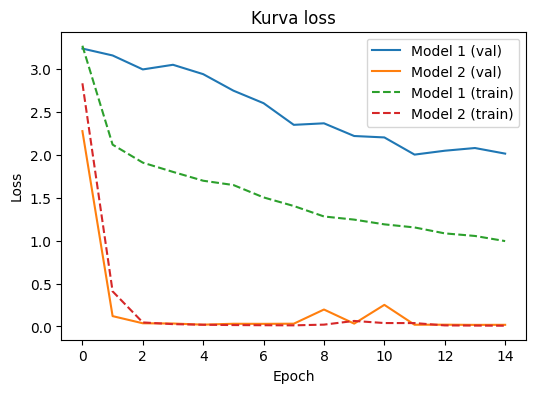

In [ ]:
plt.figure(figsize=(6, 4))
plt.plot(hist1["val"], label="Model 1 (val)")
plt.plot(hist2["val"], label="Model 2 (val)")
plt.plot(hist1["train"], "--", label="Model 1 (train)")
plt.plot(hist2["train"], "--", label="Model 2 (train)")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("Kurva loss"); plt.legend(); plt.show()

## 8. Decoding (greedy) pada data test

In [ ]:
def predict_all(model, loader):
    hyps = []
    for src, lens, _ in loader:
        ids, _ = model.translate(src.to(device), lens)
        hyps += [[trg_vocab.itos[i] for i in x] for x in ids]
    return hyps

refs = [s.split() for s in test_df["en_clean"]]
hyps1 = predict_all(model1, test_loader)
hyps2 = predict_all(model2, test_loader)

for i in range(3):
    print("SRC  :", test_df.loc[i, "id_clean"])
    print("REF  :", " ".join(refs[i]))
    print("M1   :", " ".join(hyps1[i]))
    print("M2   :", " ".join(hyps2[i]))
    print()

SRC  : budi akan membawa sepeda itu di perpustakaan minggu depan karena mereka membaca rumah mahal itu di pasar .
REF  : budi will bring the bicycle at the library next week because they read the expensive house at the market .
M1   : budi will bring the cake at the library next week then the farmer the the the at at the library .
M2   : budi will bring the bicycle at the library next week because they read the expensive house at the market .

SRC  : minggu depan mahasiswa akan mengambil sepatu itu di taman tetapi mereka akan menulis laptop bagus itu di pasar besok kemudian mahasiswa menulis meja kecil itu .
REF  : next week the student will take the shoe in the park but they will write the good laptop at the market tomorrow then the student wrote the small table .
M1   : next week the student will take the hat in the shop then the will will the the cheap in in the park tomorrow .
M2   : next week the student will take the shoe in the park but they will write the good laptop at the mar

## 9. Evaluasi: BLEU
BLEU corpus-level (n-gram 1–4, dengan brevity penalty), diimplementasikan manual agar tidak butuh library tambahan. Dihitung keseluruhan dan per kelompok panjang kalimat (pendek / sedang / panjang).

In [ ]:
def ngrams(tokens, n):
    return collections.Counter(tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1))

def bleu_scores(refs, hyps, max_n=4):
    clip, tot, rl, hl = [0] * max_n, [0] * max_n, 0, 0
    for r, h in zip(refs, hyps):
        rl += len(r); hl += len(h)
        for n in range(1, max_n + 1):
            hn, rn = ngrams(h, n), ngrams(r, n)
            clip[n - 1] += sum(min(c, rn[g]) for g, c in hn.items())
            tot[n - 1] += max(len(h) - n + 1, 0)

    p = [c / t if t > 0 else 0.0 for c, t in zip(clip, tot)]      # precision p1..p4
    bp = 0.0 if hl == 0 else (1.0 if hl > rl else math.exp(1 - rl / hl))

    scores = {}
    for n in range(1, max_n + 1):
        if min(p[:n]) == 0:
            scores[f"BLEU-{n}"] = 0.0
        else:
            scores[f"BLEU-{n}"] = bp * math.exp(sum(math.log(x) for x in p[:n]) / n)
    return scores

# (dipakai oleh cell visualisasi attention, jangan dihapus)
test_df["len"] = test_df["id_clean"].str.split().str.len()
def bucket(n):
    return "pendek (<=12)" if n <= 12 else ("sedang (13-24)" if n <= 24 else "panjang (>=25)")
test_df["bucket"] = test_df["len"].apply(bucket)

hasil = pd.DataFrame({
    "Model 1 (tanpa attention)": bleu_scores(refs, hyps1),
    "Model 2 (+ attention)": bleu_scores(refs, hyps2),
}).T
hasil.round(4)

,BLEU-1,BLEU-2,BLEU-3,BLEU-4
Model 1 (tanpa attention),0.6692,0.5347,0.4413,0.3676
Model 2 (+ attention),0.9888,0.9826,0.9766,0.9715


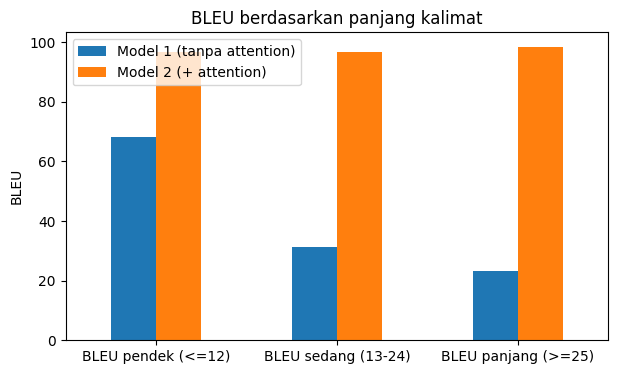

In [ ]:
cols = ["BLEU pendek (<=12)", "BLEU sedang (13-24)", "BLEU panjang (>=25)"]
hasil[cols].T.plot(kind="bar", figsize=(7, 4), rot=0)
plt.ylabel("BLEU"); plt.title("BLEU berdasarkan panjang kalimat"); plt.show()

## 10. Contoh prediksi benar dan salah

In [ ]:
def show_examples(name, hyps, k=4):
    benar = [i for i in range(len(refs)) if refs[i] == hyps[i]]
    salah = [i for i in range(len(refs)) if refs[i] != hyps[i]]
    print(f"===== {name}: {len(benar)} benar, {len(salah)} salah dari {len(refs)} kalimat test =====")
    print("\n--- Contoh BENAR ---")
    for i in benar[:k]:
        print("SRC:", test_df.loc[i, "id_clean"]); print("REF:", " ".join(refs[i])); print("HYP:", " ".join(hyps[i])); print()
    print("--- Contoh SALAH ---")
    for i in salah[:k]:
        print("SRC:", test_df.loc[i, "id_clean"]); print("REF:", " ".join(refs[i])); print("HYP:", " ".join(hyps[i])); print()

show_examples("Model 1 (tanpa attention)", hyps1)
show_examples("Model 2 (+ attention)", hyps2)

===== Model 1 (tanpa attention): 42 benar, 558 salah dari 600 kalimat test =====

--- Contoh BENAR ---
SRC: ibu saya akan membawa laptop murah itu di rumah besok .
REF: my mother will bring the cheap laptop at home tomorrow .
HYP: my mother will bring the cheap laptop at home tomorrow .

SRC: dokter akan menulis topi itu .
REF: the doctor will write the hat .
HYP: the doctor will write the hat .

SRC: tadi pagi budi menjual laptop itu di taman .
REF: this morning budi sold the laptop in the park .
HYP: this morning budi sold the laptop in the park .

SRC: siti memakai surat itu .
REF: siti uses the letter .
HYP: siti uses the letter .

--- Contoh SALAH ---
SRC: budi akan membawa sepeda itu di perpustakaan minggu depan karena mereka membaca rumah mahal itu di pasar .
REF: budi will bring the bicycle at the library next week because they read the expensive house at the market .
HYP: budi will bring the cake at the library next week then the farmer the the the at at the library .

SRC: mi

## 11. Visualisasi attention / alignment (Model 2)
Sumbu-x: kata sumber (Indonesia), sumbu-y: kata hasil terjemahan (Inggris). Warna lebih terang = bobot attention lebih besar. Perhatikan pola yang tidak berurutan, misalnya *"buku baru itu"* → *"the new book"* (urutan kata sifat dan kata benda berbeda).

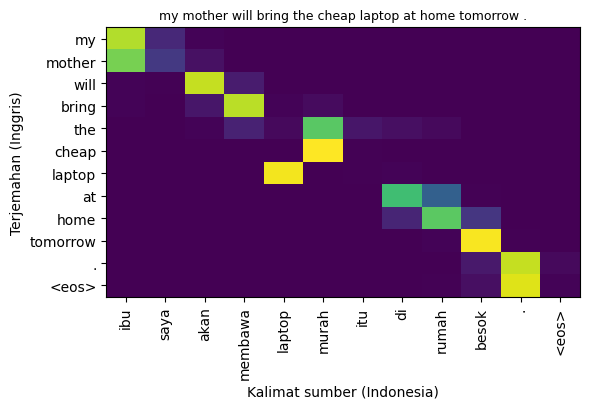

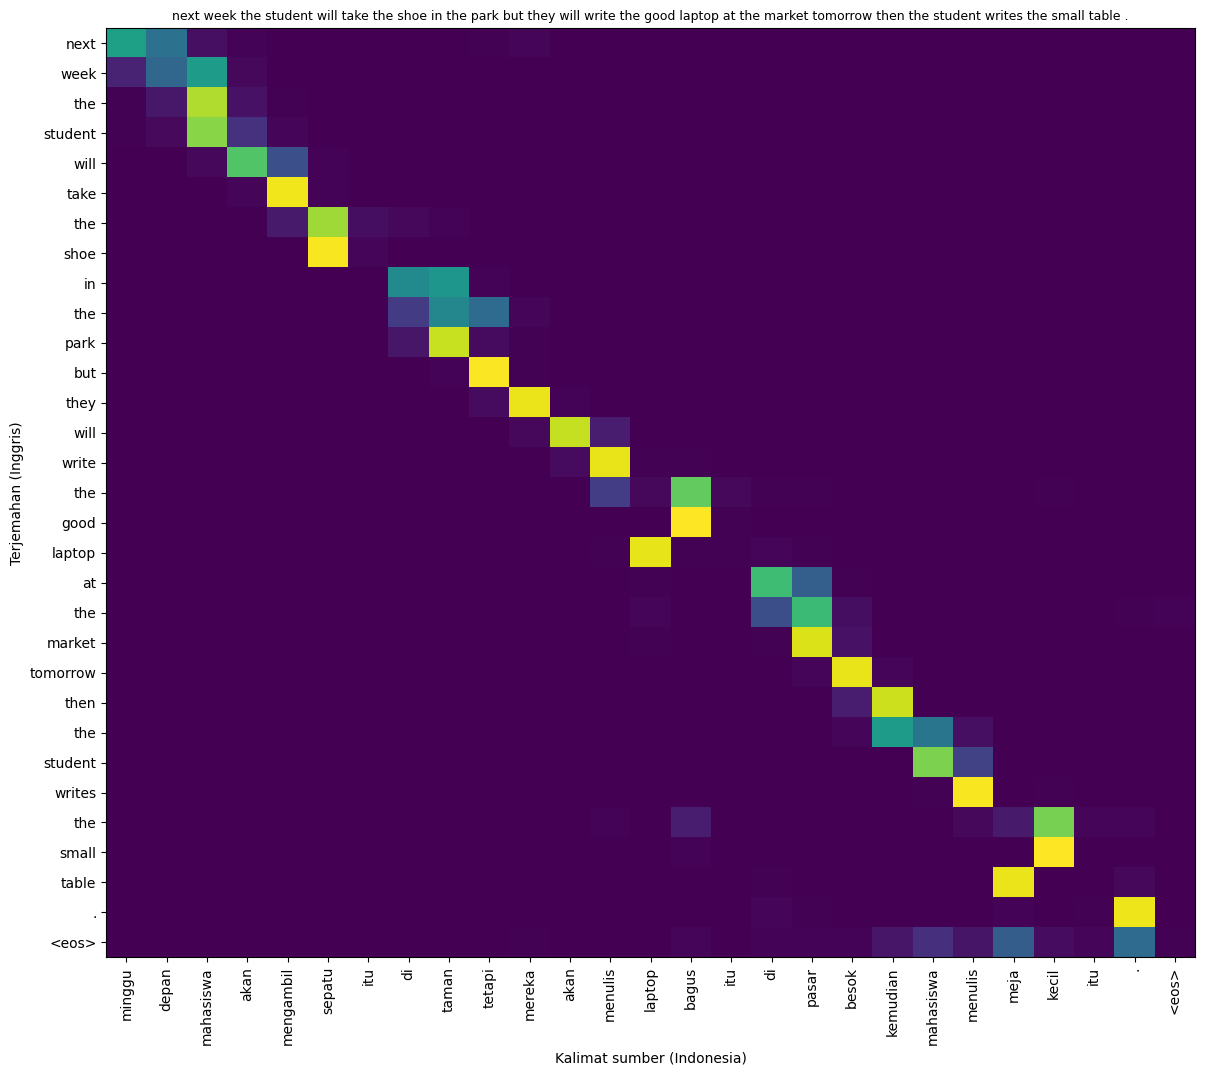

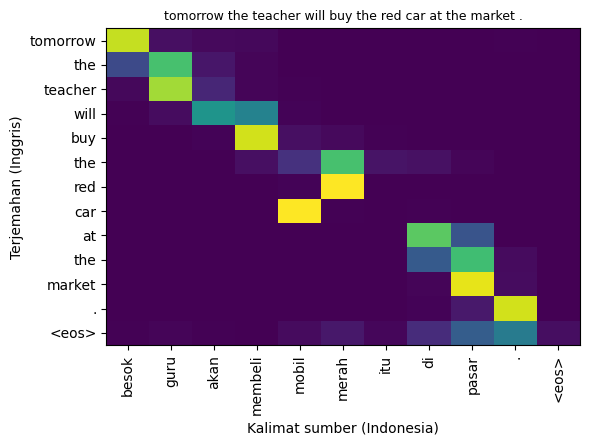

In [ ]:
def plot_attention(model, sentence, ax=None):
    s = clean(sentence)
    ids = src_vocab.encode(s) + [EOS]
    src = torch.tensor([ids], device=device)
    lens = torch.tensor([len(ids)])
    pred, attn = model.translate(src, lens)
    pred, attn = pred[0], attn[0]
    T = len(pred) + 1                          # termasuk <eos>
    attn = attn[:T, :len(ids)]
    xl = s.split() + ["<eos>"]
    yl = [trg_vocab.itos[i] for i in pred] + ["<eos>"]
    show = ax is None
    if ax is None:
        _, ax = plt.subplots(figsize=(max(6, len(xl) * 0.45), max(4, len(yl) * 0.35)))
    ax.imshow(attn, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(xl))); ax.set_xticklabels(xl, rotation=90)
    ax.set_yticks(range(len(yl))); ax.set_yticklabels(yl)
    ax.set_xlabel("Kalimat sumber (Indonesia)"); ax.set_ylabel("Terjemahan (Inggris)")
    ax.set_title(" ".join(yl[:-1]), fontsize=9)
    if show:
        plt.tight_layout(); plt.show()

# satu kalimat pendek dan satu kalimat panjang dari data test
i_pendek = test_df.index[test_df["bucket"] == "pendek (<=12)"][0]
i_panjang = test_df.index[test_df["bucket"] == "panjang (>=25)"][0]
plot_attention(model2, test_df.loc[i_pendek, "id"])
plot_attention(model2, test_df.loc[i_panjang, "id"])

# kamu juga bisa mencoba kalimat sendiri (pakai kosakata dataset):
plot_attention(model2, "Besok guru akan membeli mobil merah itu di pasar.")

## 12. Analisis error
Setiap kalimat test dibandingkan kata-per-kata dengan referensi (`difflib`). Kita hitung jenis error (substitusi / kata hilang / kata berlebih), kata referensi yang paling sering salah, dan tingkat error menurut posisi kata dalam kalimat (awal → akhir). Pada model tanpa attention, error biasanya menumpuk di bagian akhir kalimat panjang.

Jenis error (jumlah kata)
                 Model 1  Model 2
substitusi kata     3089      116
kata hilang          739        0
kata berlebih        343        0

Kata referensi yang paling sering salah - Model 1: [('the', 179), ('car', 98), ('chair', 91), ('in', 91), ('book', 91), ('because', 88), ('laptop', 84), ('house', 83)]
Kata referensi yang paling sering salah - Model 2: [('took', 12), ('made', 9), ('wrote', 8), ('brought', 8), ('saw', 7), ('writes', 6), ('bought', 6), ('used', 6)]


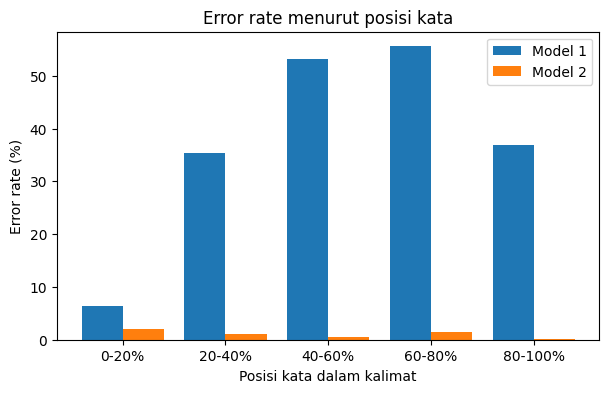

In [ ]:
def analyse(hyps):
    ops, missed = collections.Counter(), collections.Counter()
    pos_wrong, pos_total = np.zeros(5), np.zeros(5)
    for r, h in zip(refs, hyps):
        wrong = [True] * len(r)
        for tag, i1, i2, j1, j2 in difflib.SequenceMatcher(None, r, h, autojunk=False).get_opcodes():
            if tag == "equal":
                for i in range(i1, i2):
                    wrong[i] = False
            elif tag == "replace":
                ops["substitusi kata"] += i2 - i1
            elif tag == "delete":
                ops["kata hilang"] += i2 - i1
            elif tag == "insert":
                ops["kata berlebih"] += j2 - j1
            if tag in ("replace", "delete"):
                for i in range(i1, i2):
                    missed[r[i]] += 1
        for i, w in enumerate(wrong):
            b = min(int(5 * i / len(r)), 4)
            pos_total[b] += 1; pos_wrong[b] += w
    return ops, missed, 100 * pos_wrong / np.maximum(pos_total, 1)

ops1, missed1, pos1 = analyse(hyps1)
ops2, missed2, pos2 = analyse(hyps2)

print("Jenis error (jumlah kata)")
print(pd.DataFrame({"Model 1": ops1, "Model 2": ops2}).fillna(0).astype(int))
print("\nKata referensi yang paling sering salah - Model 1:", missed1.most_common(8))
print("Kata referensi yang paling sering salah - Model 2:", missed2.most_common(8))

labels = ["0-20%", "20-40%", "40-60%", "60-80%", "80-100%"]
x = np.arange(5)
plt.figure(figsize=(7, 4))
plt.bar(x - 0.2, pos1, 0.4, label="Model 1")
plt.bar(x + 0.2, pos2, 0.4, label="Model 2")
plt.xticks(x, labels)
plt.xlabel("Posisi kata dalam kalimat"); plt.ylabel("Error rate (%)")
plt.title("Error rate menurut posisi kata"); plt.legend(); plt.show()